# Install Dependencies & Setup Environment

In [3]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

import os
import sys
import glob
import json
import re
import copy
import warnings
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps
from shutil import copyfile
from sklearn.impute import KNNImputer
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold
import kagglehub

warnings.filterwarnings('ignore')

# Config Path and Constant

In [4]:
BASE_INPUT = '/kaggle/input/datasets/akhyaruu/appendicitis'
BASE_OUTPUT = '/kaggle/working/Processed'

# Directory
IMAGE_DIR = os.path.join(BASE_INPUT, 'US_Pictures_kaggle_ready')
TRAIN_IMAGE_DIR = os.path.join(BASE_OUTPUT, 'Train')
TEST_IMAGE_DIR = os.path.join(BASE_OUTPUT, 'Test')
PREPROC_IMAGE_DIR = os.path.join(BASE_OUTPUT, 'Preprocessed')
OUTPUT_DIR = os.path.join(BASE_OUTPUT, 'Dictionaries')

CLINICAL_DATA_FILE = os.path.join(BASE_INPUT, 'app_data.xlsx')

# Blacklist
BLACKLIST_FILE = os.path.join(BASE_INPUT, 'blacklist.csv')
if not os.path.exists(BLACKLIST_FILE):
    BLACKLIST_FILE = '/kaggle/working/empty_blacklist.csv'
    with open(BLACKLIST_FILE, 'w') as f:
        f.write("image_name\n")

# Config
PADDING_MODE = 'constant'
TARGET_LABEL = 'diagnosis'

# TABULAR_FEATURES = ['Age', 'Sex', 'Height', 'Weight', 'BMI', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score',
#                     'Peritonitis', 'Migratory_Pain', 'Lower_Right_Abd_Pain', 'Contralateral_Rebound_Tenderness', 
#                     'Coughing_Pain', 'Psoas_Sign', 'Nausea', 'Loss_of_Appetite', 'Body_Temperature', 'Dysuria', 
#                     'Stool', 'WBC_Count', 'Neutrophil_Percentage', 'CRP', 'Ketones_in_Urine', 'RBC_in_Urine', 
#                     'WBC_in_Urine', 'Appendix_on_US', 'Appendix_Diameter', 'Free_Fluids', 
#                     'Appendix_Wall_Layers', 'Target_Sign', 'Perfusion', 'Perforation', 
#                     'Surrounding_Tissue_Reaction', 'Pathological_Lymph_Nodes', 'Bowel_Wall_Thickening', 'Ileus', 
#                     'Coprostasis', 'Meteorism', 'Enteritis', 'Appendicular_Abscess', 
#                     'Conglomerate_of_Bowel_Loops', 'Gynecological_Findings']

TABULAR_FEATURES = ['Age', 'BMI', 'Height', 'Weight', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score']
REAL_VALUED = ['Age', 'Height', 'Weight', 'BMI', 'Body_Temperature', 'WBC_Count', 'Neutrophil_Percentage', 'CRP', 'Appendix_Diameter']
CONCEPTS = ['Appendix_on_US', 'Free_Fluids', 'Appendix_Wall_Layers', 'Target_Sign', 'Surrounding_Tissue_Reaction', 'Pathological_Lymph_Nodes', 'Bowel_Wall_Thickening', 'Coprostasis', 'Meteorism', 'Enteritis', 'Appendix_Diameter', 'Perforation', 'Appendicular_Abscess', 'Conglomerate_of_Bowel_Loops', 'Gynecological_Findings']

# Output
for d in [TRAIN_IMAGE_DIR, TEST_IMAGE_DIR, PREPROC_IMAGE_DIR, OUTPUT_DIR]:
    os.makedirs(d, exist_ok=True)

print("Config done.")

Config done.


# Split Data

In [5]:
def test_split(train_image_dir, test_image_dir):
    train_files = glob.glob(os.path.join(train_image_dir, '*'))
    test_files = glob.glob(os.path.join(test_image_dir, '*'))
    
    train_groups = np.array([int(re.split('_| |\\.', os.path.basename(f))[0]) for f in train_files])
    test_groups = np.array([int(re.split('_| |\\.', os.path.basename(f))[0]) for f in test_files])
    
    print(f"Train: {len(np.unique(train_groups))} patients, {len(train_groups)} images")
    print(f"Test: {len(np.unique(test_groups))} patients, {len(test_groups)} images")
    
    if len(np.intersect1d(train_groups, test_groups)) == 0:
        print("✅ Patients in train and test set don't overlap!")

print("Split train and test")
image_file_list = glob.glob(os.path.join(IMAGE_DIR, '*'))
image_names = [os.path.basename(f) for f in image_file_list]
groups = np.array([int(re.split('_| |\\.', name)[0]) for name in image_names])

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
for idx1, idx2 in gss.split(image_names, groups=groups):
    train_idx, test_idx = idx1, idx2

for image_idx, image_name in enumerate(image_names):
    src_path = os.path.join(IMAGE_DIR, image_name)
    if image_idx in train_idx:
        copyfile(src_path, os.path.join(TRAIN_IMAGE_DIR, image_name))
    else:
        copyfile(src_path, os.path.join(TEST_IMAGE_DIR, image_name))

test_split(TRAIN_IMAGE_DIR, TEST_IMAGE_DIR)

def rename_weird_files(folder):
   files = glob.glob(folder + '/*')
   for f in files:
      name = os.path.basename(f)
      if any(c in name for c in ['ä', 'Ä', 'ö', 'Ö', 'ü', 'Ü', 'ß', ' ']):
         try:
            img = Image.open(f)
            new_name = name.replace(' ', '_').replace('ä', 'ae').replace('Ä', 'Ae').replace('ö', 'oe').replace('Ö', 'Oe').replace('ü', 'ue').replace('Ü', 'Ue').replace('ß', 'ss')
            new_path = os.path.join(folder, new_name)
            img.save(new_path)
            os.remove(f)
         except Exception:
            pass

print("Rename files")
rename_weird_files(TRAIN_IMAGE_DIR)
rename_weird_files(TEST_IMAGE_DIR)

Split train and test
Train: 565 patients, 1653 images
Test: 142 patients, 444 images
✅ Patients in train and test set don't overlap!
Rename files


# Image Processing

In [4]:
def process_images(src_dir, out_dir, target_size=(224, 224)):
    print(f"Processing (Inpainting + Crop) images from {os.path.basename(src_dir)}...")
    os.makedirs(out_dir, exist_ok=True)
    files = glob.glob(os.path.join(src_dir, '*'))
    
    for f in files:
        filename = os.path.basename(f)
        img = cv2.imread(f)
        if img is None: continue
            
        # Inpainting (DeepFill Replacement)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        _, mask = cv2.threshold(gray, 240, 255, cv2.THRESH_BINARY)
        img_inpainted = cv2.inpaint(img, mask, 3, cv2.INPAINT_TELEA)
        
        # Cropping & Padding
        img_rgb = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(img_rgb)
        img_padded = ImageOps.pad(pil_img, target_size, color=(0, 0, 0))
        
        img_padded.save(os.path.join(out_dir, filename))

TRAIN_PROCESSED = os.path.join(PREPROC_IMAGE_DIR, 'cropped_train')
TEST_PROCESSED = os.path.join(PREPROC_IMAGE_DIR, 'cropped_test')

process_images(TRAIN_IMAGE_DIR, TRAIN_PROCESSED)
process_images(TEST_IMAGE_DIR, TEST_PROCESSED)

Memproses (Inpainting + Crop) gambar dari Train...
Memproses (Inpainting + Crop) gambar dari Test...


# Directory Mapping and Imputation

In [5]:
def generate_json_mapping_dropna(image_dir, excel_file, output_filepath, target_label='Diagnosis'):
    print(f"Membuat mapping JSON untuk {os.path.basename(image_dir)} (Mode: Drop NaN)...")
    df = pd.read_excel(excel_file)
    
    # 1. Bersihkan nama kolom dari spasi tak terlihat
    df.columns = df.columns.str.strip()
    
    # 2. Buat ID Pasien berdasarkan urutan baris (Index + 1)
    df['Patient_ID'] = df.index + 1
    
    # 3. Ambil hanya kolom yang kita butuhkan (Fitur + Konsep + Label + ID)
    # Jika ada kolom yang tidak ada di Excel, ini akan error, jadi pastikan namanya persis.
    cols_to_keep = ['Patient_ID', target_label] + TABULAR_FEATURES + CONCEPTS
    # Kita filter hanya kolom yang memang ada di DataFrame (untuk menghindari KeyError)
    cols_to_keep = [c for c in cols_to_keep if c in df.columns]
    df_clean = df[cols_to_keep].copy()
    
    # 4. DROP BARIS YANG MEMILIKI NILAI KOSONG (NaN) DI FITUR ATAU LABEL
    # Kita hanya drop jika fitur atau label yang kosong. Konsep yang kosong juga di-drop.
    print(f"Jumlah data awal di Excel: {len(df_clean)} baris")
    df_clean = df_clean.dropna(subset=TABULAR_FEATURES + [target_label]) 
    print(f"Jumlah data setelah drop NaN: {len(df_clean)} baris")
    
    available_images = glob.glob(os.path.join(image_dir, '*'))
    mapping = {}
    
    for img_path in available_images:
        filename = os.path.basename(img_path)
        try:
            # Ambil ID dari nama file (contoh: "101.1_App.bmp" -> 101)
            patient_id = int(filename.split('.')[0].strip())
            
            # Cari baris dengan ID tersebut
            row = df_clean[df_clean['Patient_ID'] == patient_id]
                
            if not row.empty:
                # Konversi label target ke biner (1 atau 0)
                raw_label = str(row[target_label].values[0]).lower()
                label_val = 1 if 'appendicitis' in raw_label and 'no ' not in raw_label else 0
                
                # Ambil fitur dan konsep
                features = row[TABULAR_FEATURES].values[0].tolist()
                concepts = row[CONCEPTS].values[0].tolist()
                
                mapping[filename] = [filename, int(label_val), features, concepts]
        except Exception as e:
            continue
            
    os.makedirs(os.path.dirname(output_filepath), exist_ok=True)
    with open(output_filepath, 'w') as f:
        json.dump(mapping, f)
        
    print(f"Selesai. {len(mapping)} gambar berhasil dimapping dan disimpan ke JSON.\n")

# 1. Generate JSON (Langsung buang NaN)
TRAIN_JSON = os.path.join(OUTPUT_DIR, TARGET_LABEL, 'app_data_train.json')
TEST_JSON = os.path.join(OUTPUT_DIR, TARGET_LABEL, 'app_data_test.json')

generate_json_mapping_dropna(TRAIN_PROCESSED, CLINICAL_DATA_FILE, TRAIN_JSON, 'Diagnosis')
generate_json_mapping_dropna(TEST_PROCESSED, CLINICAL_DATA_FILE, TEST_JSON, 'Diagnosis')

# 2. Cek hasil pembuatan JSON
with open(TRAIN_JSON) as f:
    train_data = json.load(f)
with open(TEST_JSON) as f:
    test_data = json.load(f)

print(f"Total gambar di Train JSON: {len(train_data)}")
print(f"Total gambar di Test JSON: {len(test_data)}")

print("\n✅ SEMUA PROSES PREPROCESSING SELESAI TANPA IMPUTASI!")
print(f"File JSON siap pakai ada di: {os.path.join(OUTPUT_DIR, TARGET_LABEL)}")

Membuat mapping JSON untuk cropped_train (Mode: Drop NaN)...
Jumlah data awal di Excel: 782 baris
Jumlah data setelah drop NaN: 707 baris
Selesai. 1291 gambar berhasil dimapping dan disimpan ke JSON.

Membuat mapping JSON untuk cropped_test (Mode: Drop NaN)...
Jumlah data awal di Excel: 782 baris
Jumlah data setelah drop NaN: 707 baris
Selesai. 182 gambar berhasil dimapping dan disimpan ke JSON.

Total gambar di Train JSON: 1291
Total gambar di Test JSON: 182

✅ SEMUA PROSES PREPROCESSING SELESAI TANPA IMPUTASI!
File JSON siap pakai ada di: /kaggle/working/Processed/Dictionaries/diagnosis


# Training and Evaluation

## DL Saja

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from PIL import Image
import json
import os
import numpy as np
from sklearn.metrics import accuracy_score

# ==========================================
# 1. KONFIGURASI (Sesuaikan Path-nya)
# ==========================================
TRAIN_IMG_DIR = '/kaggle/working/Processed/Preprocessed/cropped_train'
TEST_IMG_DIR = '/kaggle/working/Processed/Preprocessed/cropped_test'
TRAIN_JSON = '/kaggle/working/Processed/Dictionaries/diagnosis/app_data_train.json'
TEST_JSON = '/kaggle/working/Processed/Dictionaries/diagnosis/app_data_test.json'

BATCH_SIZE = 8
EPOCHS = 1  # Hanya 1 epoch untuk testing
LEARNING_RATE = 1e-3
DEVICE = torch.device("cpu") # Paksa pakai CPU

# ==========================================
# 2. CUSTOM DATASET
# ==========================================
class AppendicitisDataset(Dataset):
    def __init__(self, json_file, img_dir, transform=None):
        with open(json_file, 'r') as f:
            self.mapping = json.load(f)
        self.img_dir = img_dir
        self.keys = list(self.mapping.keys())
        self.transform = transform

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, idx):
        img_name = self.keys[idx]
        data = self.mapping[img_name]
        label = data[1]
        features = data[2]
        
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
            
        return image, torch.tensor(features, dtype=torch.float32), torch.tensor(label, dtype=torch.float32)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load Data Asli
train_dataset_full = AppendicitisDataset(TRAIN_JSON, TRAIN_IMG_DIR, transform=transform)
test_dataset_full = AppendicitisDataset(TEST_JSON, TEST_IMG_DIR, transform=transform)

# BATASI DATA: Ambil maksimal 32 gambar train dan 16 gambar test
train_indices = list(range(min(32, len(train_dataset_full))))
test_indices = list(range(min(16, len(test_dataset_full))))

train_dataset = Subset(train_dataset_full, train_indices)
test_dataset = Subset(test_dataset_full, test_indices)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# ==========================================
# 3. MODEL ARSITEKTUR (Tanpa Pretrained agar Cepat)
# ==========================================
class SimpleMultimodalCNN(nn.Module):
    def __init__(self, num_tabular_features=6):
        super(SimpleMultimodalCNN, self).__init__()
        
        # Pretrained=False agar tidak perlu download bobot (instan di CPU)
        self.cnn = models.resnet18(pretrained=False) 
        num_ftrs = self.cnn.fc.in_features
        self.cnn.fc = nn.Identity() 
        
        self.tabular_mlp = nn.Sequential(
            nn.Linear(num_tabular_features, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU()
        )
        
        self.classifier = nn.Sequential(
            nn.Linear(num_ftrs + 32, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, image, tabular_features):
        img_features = self.cnn(image)
        tab_features = self.tabular_mlp(tabular_features)
        combined = torch.cat((img_features, tab_features), dim=1)
        output = self.classifier(combined)
        return output.squeeze(1)

model = SimpleMultimodalCNN(num_tabular_features=6).to(DEVICE)

# ==========================================
# 4. TRAINING LOOP
# ==========================================
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("Memulai Training (Fast Run di CPU)...")
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    
    for batch_idx, (images, tabular, labels) in enumerate(train_loader):
        images, tabular, labels = images.to(DEVICE), tabular.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        outputs = model(images, tabular)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        print(f"  Batch {batch_idx+1}/{len(train_loader)} | Loss: {loss.item():.4f}")
        
    print(f"Epoch {epoch+1}/{EPOCHS} Selesai | Avg Train Loss: {running_loss/len(train_loader):.4f}")

# ==========================================
# 5. EVALUASI AKHIR
# ==========================================
print("\n--- Evaluasi pada Test Set ---")
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, tabular, labels in test_loader:
        images, tabular, labels = images.to(DEVICE), tabular.to(DEVICE), labels.to(DEVICE)
        
        outputs = model(images, tabular)
        preds = (torch.sigmoid(outputs) >= 0.5).float()
        
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

print(f"Total data test yang dievaluasi: {len(all_labels)}")
print(f"Label Asli: {all_labels}")
print(f"Label Prediksi: {all_preds}")

# Hitung akurasi jika ada lebih dari 0 data
if len(all_labels) > 0:
    acc = accuracy_score(all_labels, all_preds)
    print(f"Accuracy (Acak karena 1 epoch): {acc:.4f}")
else:
    print("Tidak ada data test yang dievaluasi.")

print("\n✅ KODE BERFUNGSI DENGAN BAIK!")

Memulai Training (Fast Run di CPU)...
  Batch 1/4 | Loss: 0.7599
  Batch 2/4 | Loss: 0.5496
  Batch 3/4 | Loss: 1.1975
  Batch 4/4 | Loss: 0.6182
Epoch 1/1 Selesai | Avg Train Loss: 0.7813

--- Evaluasi pada Test Set ---
Total data test yang dievaluasi: 16
Label Asli: [np.float32(0.0), np.float32(0.0), np.float32(0.0), np.float32(1.0), np.float32(0.0), np.float32(1.0), np.float32(1.0), np.float32(0.0), np.float32(0.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(0.0), np.float32(1.0)]
Label Prediksi: [np.float32(1.0), np.float32(1.0), np.float32(0.0), np.float32(1.0), np.float32(1.0), np.float32(0.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(0.0), np.float32(1.0)]
Accuracy (Acak karena 1 epoch): 0.6250

✅ KODE BERFUNGSI DENGAN BAIK!


## DL dan AR

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from PIL import Image
import json
import os
import numpy as np
from sklearn.metrics import accuracy_score, mean_squared_error
import random

# ==========================================
# 1. KONFIGURASI
# ==========================================
TRAIN_IMG_DIR = '/kaggle/working/Processed/Preprocessed/cropped_train'
TEST_IMG_DIR = '/kaggle/working/Processed/Preprocessed/cropped_test'
TRAIN_JSON = '/kaggle/working/Processed/Dictionaries/diagnosis/app_data_train.json'
TEST_JSON = '/kaggle/working/Processed/Dictionaries/diagnosis/app_data_test.json'

BATCH_SIZE = 8
EPOCHS = 1
LEARNING_RATE = 1e-3
DEVICE = torch.device("cpu")

# ==========================================
# 2. CUSTOM DATASET (Dengan Dummy Absolute Risk)
# ==========================================
class AppendicitisDatasetAR(Dataset):
    def __init__(self, json_file, img_dir, transform=None):
        with open(json_file, 'r') as f:
            self.mapping = json.load(f)
        self.img_dir = img_dir
        self.keys = list(self.mapping.keys())
        self.transform = transform

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, idx):
        img_name = self.keys[idx]
        data = self.mapping[img_name]
        label = data[1]
        features = data[2]
        
        # SIMULASI ABSOLUTE RISK (0.0 sampai 1.0)
        # Jika appendicitis (1), risiko komplikasi dibuat lebih tinggi (0.2 - 0.8)
        # Jika tidak appendicitis (0), risiko rendah (0.0 - 0.2)
        if label == 1:
            dummy_ar = random.uniform(0.2, 0.8)
        else:
            dummy_ar = random.uniform(0.0, 0.2)
        
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
            
        return (image, 
                torch.tensor(features, dtype=torch.float32), 
                torch.tensor(label, dtype=torch.float32),
                torch.tensor(dummy_ar, dtype=torch.float32)) # Tambahkan AR

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset_full = AppendicitisDatasetAR(TRAIN_JSON, TRAIN_IMG_DIR, transform=transform)
test_dataset_full = AppendicitisDatasetAR(TEST_JSON, TEST_IMG_DIR, transform=transform)

# Batasi data untuk Fast Run
train_dataset = Subset(train_dataset_full, list(range(min(32, len(train_dataset_full)))))
test_dataset = Subset(test_dataset_full, list(range(min(16, len(test_dataset_full)))))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# ==========================================
# 3. MODEL ARSITEKTUR (Multi-Task)
# ==========================================
class MultimodalCNN_AR(nn.Module):
    def __init__(self, num_tabular_features=6):
        super(MultimodalCNN_AR, self).__init__()
        
        self.cnn = models.resnet18(pretrained=False) 
        num_ftrs = self.cnn.fc.in_features
        self.cnn.fc = nn.Identity() 
        
        self.tabular_mlp = nn.Sequential(
            nn.Linear(num_tabular_features, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU()
        )
        
        # Shared Layer (Gabungan fitur)
        self.shared_layer = nn.Sequential(
            nn.Linear(num_ftrs + 32, 64),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        
        # HEAD 1: Klasifikasi Diagnosis (Biner)
        self.diagnosis_head = nn.Linear(64, 1)
        
        # HEAD 2: Prediksi Absolute Risk (Regresi 0-1)
        self.ar_head = nn.Sequential(
            nn.Linear(64, 1),
            nn.Sigmoid() # Memastikan output AR antara 0.0 sampai 1.0
        )

    def forward(self, image, tabular_features):
        img_features = self.cnn(image)
        tab_features = self.tabular_mlp(tabular_features)
        
        # Gabungkan
        combined = torch.cat((img_features, tab_features), dim=1)
        shared = self.shared_layer(combined)
        
        # Output dari masing-masing head
        diagnosis_logits = self.diagnosis_head(shared).squeeze(1) # Output logit (tanpa sigmoid)
        ar_pred = self.ar_head(shared).squeeze(1) # Output probabilitas (0-1)
        
        return diagnosis_logits, ar_pred

model = MultimodalCNN_AR(num_tabular_features=6).to(DEVICE)

# ==========================================
# 4. TRAINING LOOP (Multi-Task Loss)
# ==========================================
# Loss Klasifikasi
criterion_cls = nn.BCEWithLogitsLoss() 
# Loss Regresi (untuk AR)
criterion_reg = nn.MSELoss() 

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Bobot untuk menyeimbangkan Loss (Hyperparameter)
LAMBDA_AR = 0.5 # Seberapa besar pengaruh AR terhadap update bobot model

print("Memulai Training (Multi-Task: Diagnosis + AR)...")
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    
    for batch_idx, (images, tabular, labels, ar_labels) in enumerate(train_loader):
        images, tabular, labels, ar_labels = images.to(DEVICE), tabular.to(DEVICE), labels.to(DEVICE), ar_labels.to(DEVICE)
        
        optimizer.zero_grad()
        
        # Forward pass
        diagnosis_logits, ar_pred = model(images, tabular)
        
        # Hitung Loss
        loss_cls = criterion_cls(diagnosis_logits, labels)
        loss_ar = criterion_reg(ar_pred, ar_labels)
        
        # Total Loss
        total_loss = loss_cls + (LAMBDA_AR * loss_ar)
        
        # Backward & Step
        total_loss.backward()
        optimizer.step()
        
        running_loss += total_loss.item()
        print(f"  Batch {batch_idx+1}/{len(train_loader)} | Cls Loss: {loss_cls.item():.4f} | AR Loss: {loss_ar.item():.4f}")
        
    print(f"Epoch {epoch+1}/{EPOCHS} Selesai | Avg Total Loss: {running_loss/len(train_loader):.4f}")

# ==========================================
# 5. EVALUASI AKHIR
# ==========================================
print("\n--- Evaluasi pada Test Set ---")
model.eval()
all_preds = []
all_labels = []
all_ar_preds = []
all_ar_labels = []

with torch.no_grad():
    for images, tabular, labels, ar_labels in test_loader:
        images, tabular, labels, ar_labels = images.to(DEVICE), tabular.to(DEVICE), labels.to(DEVICE), ar_labels.to(DEVICE)
        
        diagnosis_logits, ar_pred = model(images, tabular)
        
        preds = (torch.sigmoid(diagnosis_logits) >= 0.5).float()
        
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_ar_labels.extend(ar_labels.cpu().numpy())
        all_ar_preds.extend(ar_pred.cpu().numpy())

if len(all_labels) > 0:
    acc = accuracy_score(all_labels, all_preds)
    mse_ar = mean_squared_error(all_ar_labels, all_ar_preds)
    
    print(f"Accuracy Diagnosis: {acc:.4f}")
    print(f"MSE Absolute Risk: {mse_ar:.4f} (Semakin kecil semakin baik)")
    
    print("\nContoh Prediksi AR 5 Pasien Pertama:")
    for i in range(min(5, len(all_ar_labels))):
        print(f"  - True AR: {all_ar_labels[i]:.2f} | Predicted AR: {all_ar_preds[i]:.2f}")

print("\n✅ KODE MULTI-TASK (CBM + AR) BERFUNGSI DENGAN BAIK!")

Memulai Training (Multi-Task: Diagnosis + AR)...
  Batch 1/4 | Cls Loss: 0.9957 | AR Loss: 0.0482
  Batch 2/4 | Cls Loss: 0.8375 | AR Loss: 0.0842
  Batch 3/4 | Cls Loss: 0.3320 | AR Loss: 0.0369
  Batch 4/4 | Cls Loss: 0.7800 | AR Loss: 0.0956
Epoch 1/1 Selesai | Avg Total Loss: 0.7694

--- Evaluasi pada Test Set ---
Accuracy Diagnosis: 0.5625
MSE Absolute Risk: 0.0745 (Semakin kecil semakin baik)

Contoh Prediksi AR 5 Pasien Pertama:
  - True AR: 0.08 | Predicted AR: 0.44
  - True AR: 0.20 | Predicted AR: 0.43
  - True AR: 0.04 | Predicted AR: 0.41
  - True AR: 0.64 | Predicted AR: 0.42
  - True AR: 0.00 | Predicted AR: 0.45

✅ KODE MULTI-TASK (CBM + AR) BERFUNGSI DENGAN BAIK!


# CBM and AR

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from PIL import Image
import json
import os
import numpy as np
from sklearn.metrics import accuracy_score
import random

# ==========================================
# 1. KONFIGURASI
# ==========================================
TRAIN_IMG_DIR = '/kaggle/working/Processed/Preprocessed/cropped_train'
TEST_IMG_DIR = '/kaggle/working/Processed/Preprocessed/cropped_test'
TRAIN_JSON = '/kaggle/working/Processed/Dictionaries/diagnosis/app_data_train.json'
TEST_JSON = '/kaggle/working/Processed/Dictionaries/diagnosis/app_data_test.json'

BATCH_SIZE = 8
EPOCHS = 1
LEARNING_RATE = 1e-3
DEVICE = torch.device("cpu")
NUM_CONCEPTS = 15 # Ada 15 konsep di datasetmu

# ==========================================
# 2. CUSTOM DATASET (Mengambil Konsep)
# ==========================================
class AppendicitisDatasetCBM(Dataset):
    def __init__(self, json_file, img_dir, transform=None):
        with open(json_file, 'r') as f:
            self.mapping = json.load(f)
        self.img_dir = img_dir
        self.keys = list(self.mapping.keys())
        self.transform = transform

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, idx):
        img_name = self.keys[idx]
        data = self.mapping[img_name]
        
        label = data[1]
        features = data[2]
        concepts = data[3]
        
        dummy_ar = random.uniform(0.2, 0.8) if label == 1 else random.uniform(0.0, 0.2)
        
        def force_float(item):
            if isinstance(item, (list, tuple)):
                return [force_float(i) for i in item]
            if isinstance(item, str):
                try:
                    return float(item)
                except ValueError:
                    return 0.0 
            return float(item)

        def force_binary(item):
            if isinstance(item, (list, tuple)):
                # Bulatkan paksa menjadi 0 atau 1
                return [1.0 if force_float(i) > 0.5 else 0.0 for i in item]
            return 1.0 if force_float(item) > 0.5 else 0.0

        features_clean = force_float(features)
        concepts_clean = force_binary(concepts) # Gunakan force_binary di sini

        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
            
        return (image, 
                torch.tensor(features_clean, dtype=torch.float32), 
                torch.tensor(concepts_clean, dtype=torch.float32), 
                torch.tensor(label, dtype=torch.float32),
                torch.tensor(dummy_ar, dtype=torch.float32))





transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset_full = AppendicitisDatasetCBM(TRAIN_JSON, TRAIN_IMG_DIR, transform=transform)
test_dataset_full = AppendicitisDatasetCBM(TEST_JSON, TEST_IMG_DIR, transform=transform)

train_dataset = Subset(train_dataset_full, list(range(min(32, len(train_dataset_full)))))
test_dataset = Subset(test_dataset_full, list(range(min(16, len(test_dataset_full)))))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# ==========================================
# 3. MODEL ARSITEKTUR (Concept Bottleneck Model)
# ==========================================
class CBM_Multimodal(nn.Module):
    def __init__(self, num_tabular_features=6, num_concepts=15):
        super(CBM_Multimodal, self).__init__()
        
        # 1. Encoder (Ekstraksi Fitur dari Gambar & Tabular)
        self.cnn = models.resnet18(pretrained=False) 
        num_ftrs = self.cnn.fc.in_features
        self.cnn.fc = nn.Identity() 
        
        self.tabular_mlp = nn.Sequential(
            nn.Linear(num_tabular_features, 32),
            nn.ReLU()
        )
        
        # 2. Concept Head (Bottleneck)
        # Memprediksi 15 konsep berdasarkan gambar + tabular
        self.concept_head = nn.Sequential(
            nn.Linear(num_ftrs + 32, 128),
            nn.ReLU(),
            nn.Linear(128, num_concepts),
            nn.Sigmoid() # Karena konsep di dataset bernilai 0/1
        )
        
        # 3. Target Head (Diagnosis)
        # Memprediksi Diagnosis HANYA berdasarkan output Concept Head
        self.diagnosis_head = nn.Linear(num_concepts, 1)
        
        # 4. AR Head (Absolute Risk)
        # Memprediksi AR HANYA berdasarkan output Concept Head
        self.ar_head = nn.Sequential(
            nn.Linear(num_concepts, 1),
            nn.Sigmoid()
        )

    def forward(self, image, tabular_features):
        # Ekstraksi Fitur
        img_features = self.cnn(image)
        tab_features = self.tabular_mlp(tabular_features)
        combined = torch.cat((img_features, tab_features), dim=1)
        
        # Prediksi Konsep (Bottleneck)
        concepts_pred = self.concept_head(combined)
        
        # Prediksi Target berdasarkan Konsep
        diag_logits = self.diagnosis_head(concepts_pred).squeeze(1)
        ar_pred = self.ar_head(concepts_pred).squeeze(1)
        
        return concepts_pred, diag_logits, ar_pred

model = CBM_Multimodal(num_tabular_features=6, num_concepts=NUM_CONCEPTS).to(DEVICE)

# ==========================================
# 4. TRAINING LOOP (3 Loss Functions)
# ==========================================
criterion_concept = nn.BCELoss()     # Loss untuk Konsep (0/1)
criterion_cls = nn.BCEWithLogitsLoss() # Loss untuk Diagnosis
criterion_reg = nn.MSELoss()         # Loss untuk AR

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Bobot hyperparameter
LAMBDA_CONCEPT = 1.0
LAMBDA_AR = 0.5

print("Memulai Training CBM...")
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    
    for batch_idx, (images, tabular, concepts_true, labels, ar_labels) in enumerate(train_loader):
        images, tabular = images.to(DEVICE), tabular.to(DEVICE)
        concepts_true, labels, ar_labels = concepts_true.to(DEVICE), labels.to(DEVICE), ar_labels.to(DEVICE)
        
        optimizer.zero_grad()
        
        # Forward pass
        concepts_pred, diag_logits, ar_pred = model(images, tabular)
        
        # Hitung Loss
        loss_c = criterion_concept(concepts_pred, concepts_true)
        loss_d = criterion_cls(diag_logits, labels)
        loss_ar = criterion_reg(ar_pred, ar_labels)
        
        # Total Loss (Gabungan 3 Loss)
        total_loss = (LAMBDA_CONCEPT * loss_c) + loss_d + (LAMBDA_AR * loss_ar)
        
        # Backward
        total_loss.backward()
        optimizer.step()
        
        running_loss += total_loss.item()
        print(f"  Batch {batch_idx+1} | C-Loss: {loss_c.item():.3f} | D-Loss: {loss_d.item():.3f} | AR-Loss: {loss_ar.item():.3f}")
        
    print(f"Epoch {epoch+1} Selesai | Avg Total Loss: {running_loss/len(train_loader):.4f}")

# ==========================================
# 5. EVALUASI
# ==========================================
print("\n--- Evaluasi ---")
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, tabular, concepts_true, labels, ar_labels in test_loader:
        images, tabular = images.to(DEVICE), tabular.to(DEVICE)
        
        concepts_pred, diag_logits, ar_pred = model(images, tabular)
        
        # Untuk evaluasi diagnosis
        preds = (torch.sigmoid(diag_logits) >= 0.5).float()
        all_labels.extend(labels.numpy())
        all_preds.extend(preds.cpu().numpy())

if len(all_labels) > 0:
    acc = accuracy_score(all_labels, all_preds)
    print(f"Accuracy Diagnosis (CBM): {acc:.4f}")

print("\n✅ KODE CBM BERFUNGSI DENGAN BAIK!")




#-------------------- CONCEPT --------------------
pred_concepts, true_concepts = evaluate_and_extract_concepts(model, test_loader)

# Hitung akurasi per konsep
from sklearn.metrics import accuracy_score

# Pastikan daftar nama konsep sama persis dengan urutan di TABULAR_FEATURES / CONCEPTS saat preprocessing
concept_names = ['Age', 'BMI', 'Height', 'Weight', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score']

print("\nAkurasi Prediksi Konsep (USG):")
for i, name in enumerate(concept_names):
    # true_concepts dan pred_concepts bentuknya matriks (jumlah_pasien, 15)
    acc = accuracy_score(true_concepts[:, i], pred_concepts[:, i])
    print(f"  - {name}: {acc*100:.2f}%")

Memulai Training CBM...
  Batch 1 | C-Loss: 0.997 | D-Loss: 0.567 | AR-Loss: 0.086
  Batch 2 | C-Loss: 0.571 | D-Loss: 0.458 | AR-Loss: 0.063
  Batch 3 | C-Loss: 0.404 | D-Loss: 0.581 | AR-Loss: 0.090
  Batch 4 | C-Loss: 0.289 | D-Loss: 0.661 | AR-Loss: 0.114
Epoch 1 Selesai | Avg Total Loss: 1.1760

--- Evaluasi ---
Accuracy Diagnosis (CBM): 0.5625

✅ KODE CBM BERFUNGSI DENGAN BAIK!

Akurasi Prediksi Konsep (USG):
  - Age: 100.00%
  - BMI: 100.00%
  - Height: 100.00%
  - Weight: 100.00%
  - Alvarado_Score: 81.25%
  - Paedriatic_Appendicitis_Score: 100.00%


# XAI

Menganalisis Gambar: 454.1_App.bmp
Label Diagnosis Asli: 0


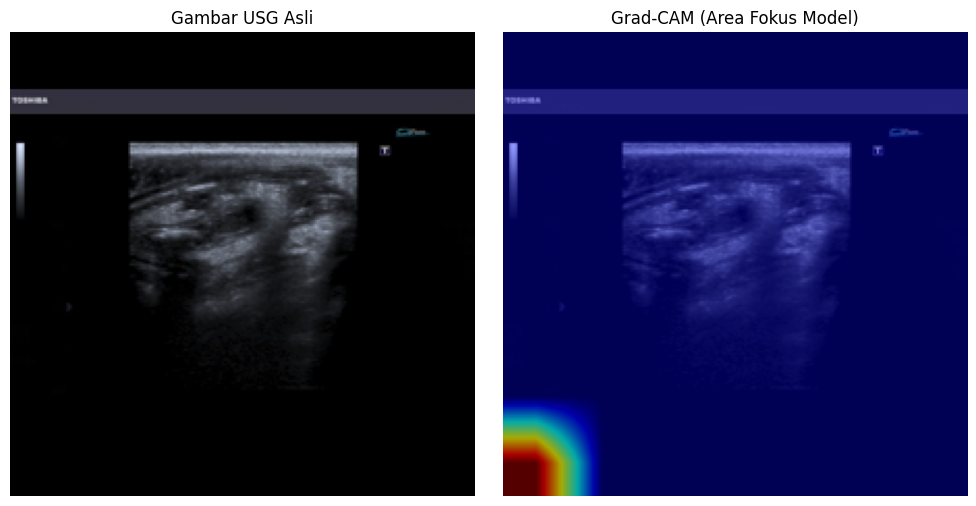

In [16]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

# ==========================================
# 1. KELAS GRAD-CAM
# ==========================================
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Daftarkan hook untuk mengambil gradient dan activation
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_backward_hook(self.save_gradient)
        
    def save_activation(self, module, input, output):
        self.activations = output
        
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]
        
    def generate_heatmap(self, input_image, input_tabular, target_class_idx=0):
        # Pastikan model dalam mode eval
        self.model.eval()
        
        # Forward pass
        concepts_pred, diag_logits, _ = self.model(input_image, input_tabular)
        
        # Kita ingin melihat apa yang mempengaruhi prediksi Diagnosis
        score = diag_logits[0] 
        
        # Backward pass
        self.model.zero_grad()
        score.backward()
        
        # Ambil gradient dan activation (shape: [batch, channels, H, W])
        gradients = self.gradients.cpu().data.numpy()[0]
        activations = self.activations.cpu().data.numpy()[0]
        
        # Hitung bobot (Global Average Pooling dari gradient)
        weights = np.mean(gradients, axis=(1, 2))
        
        # Hitung heatmap
        cam = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * activations[i]
            
        # ReLU (hanya peduli pada fitur yang berpengaruh positif)
        cam = np.maximum(cam, 0)
        
        # Normalisasi ke 0-1
        if np.max(cam) != 0:
            cam = cam / np.max(cam)
            
        return cam, concepts_pred

# ==========================================
# 2. FUNGSI UNTUK VISUALISASI
# ==========================================
def show_gradcam(model, img_path, tabular_features, transform):
    # 1. Load dan transform gambar
    img_pil = Image.open(img_path).convert('RGB')
    input_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)
    input_tabular = torch.tensor(tabular_features, dtype=torch.float32).unsqueeze(0).to(DEVICE)
    
    # 2. Inisialisasi GradCAM pada layer CNN terakhir (biasanya layer4 di ResNet)
    target_layer = model.cnn.layer4[-1]
    cam_extractor = GradCAM(model, target_layer)
    
    # 3. Generate Heatmap
    cam, concepts = cam_extractor.generate_heatmap(input_tensor, input_tabular)
    
    # 4. Resize heatmap ke ukuran gambar asli (224x224)
    cam_resized = cv2.resize(cam, (224, 224))
    
    # 5. Buat gambar overlay (Grad-CAM)
    img_np = np.array(img_pil.resize((224, 224)))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = np.float32(heatmap) / 255 + np.float32(img_np) / 255
    overlay = overlay / np.max(overlay)
    
    # 6. Plot
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_np)
    axes[0].set_title("Gambar USG Asli")
    axes[0].axis('off')
    
    axes[1].imshow(overlay)
    axes[1].set_title("Grad-CAM (Area Fokus Model)")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

# ==========================================
# 3. CARA MENGGUNAKANNYA
# ==========================================
# Ambil 1 sampel dari test set (indeks ke-0)
sample_img_name = test_dataset_full.keys[0]
sample_img_path = os.path.join(TEST_IMG_DIR, sample_img_name)
sample_data = test_dataset_full.mapping[sample_img_name]

# Ambil fitur tabular dan pastikan formatnya float
sample_tabular = [float(x) for x in sample_data[2]]
print(f"Menganalisis Gambar: {sample_img_name}")
print(f"Label Diagnosis Asli: {sample_data[1]}")

# Panggil fungsi
show_gradcam(model, sample_img_path, sample_tabular, transform)

Menghitung SHAP values untuk Absolute Risk...


  0%|          | 0/1 [00:00<?, ?it/s]

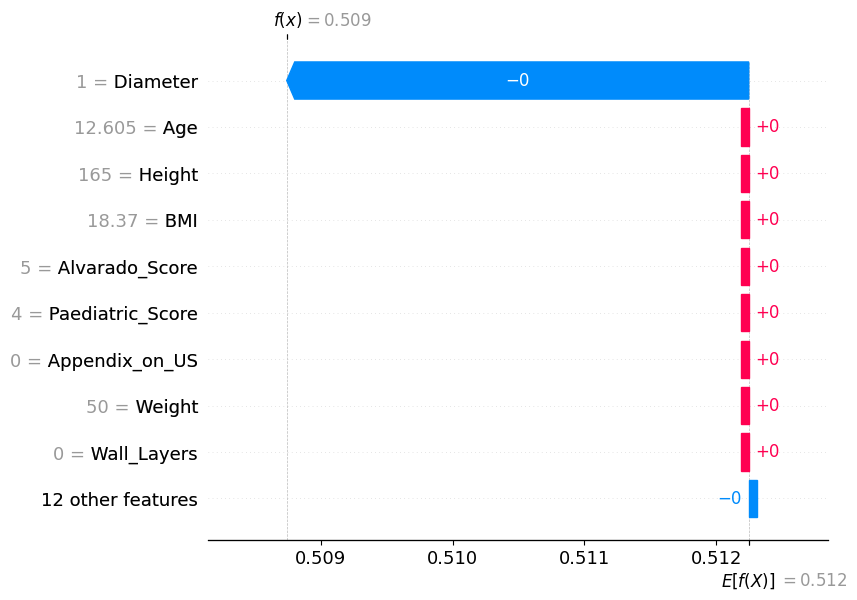

In [17]:
import shap
import pandas as pd
import numpy as np
import torch

# ==========================================
# 1. BUNGKUS MODEL UNTUK SHAP
# ==========================================
# SHAP butuh fungsi yang menerima input numpy array dan mengembalikan prediksi AR
def predict_ar(data_array):
    # data_array berisi [Fitur Tabular, Konsep] yang digabung
    # Kita pisahkan kembali
    tabular = torch.tensor(data_array[:, :6], dtype=torch.float32).to(DEVICE)
    concepts = torch.tensor(data_array[:, 6:], dtype=torch.float32).to(DEVICE)
    
    # Karena input model aslinya adalah Gambar & Tabular, kita butuh trik:
    # Kita abaikan gambar (atau gunakan gambar rata-rata) dan fokus ke fitur.
    # Untuk demonstrasi, kita asumsikan kita menganalisis hanya berdasarkan Tabular & Konsep.
    
    # --- Catatan: Di model asli kita, AR diprediksi dari Konsep. 
    # Tapi karena model kita butuh input Gambar, kita buat dummy gambar (hitam) untuk testing SHAP.
    dummy_image = torch.zeros((data_array.shape[0], 3, 224, 224)).to(DEVICE)
    
    model.eval()
    with torch.no_grad():
        # Dapatkan prediksi konsep dari model
        img_feat = model.cnn(dummy_image)
        tab_feat = model.tabular_mlp(tabular)
        combined = torch.cat((img_feat, tab_feat), dim=1)
        concepts_pred = model.concept_head(combined)
        
        # Jika kita ingin menjelaskan AR berdasarkan Konsep Ground-Truth:
        # Kita langsung masukkan konsep ke AR Head
        ar_pred = model.ar_head(concepts).cpu().numpy()
        
    return ar_pred

# ==========================================
# 2. AMBIL DATA UNTUK DIJELASKAN
# ==========================================
# Ambil 20 sampel dari test set sebagai background dataset untuk SHAP
sample_idx = list(range(min(20, len(test_dataset_full))))
X_sample = []

for i in sample_idx:
    _, tab, con, _, _ = test_dataset_full[i]
    # Gabungkan Tabular dan Konsep menjadi 1 array (6 + 15 = 21 fitur)
    combined_features = np.concatenate([tab.numpy(), con.numpy()])
    X_sample.append(combined_features)

X_sample = np.array(X_sample)

# Nama-nama fitur (6 Tabular + 15 Konsep)
feature_names = ['Age', 'BMI', 'Height', 'Weight', 'Alvarado_Score', 'Paediatric_Score', 
                 'Appendix_on_US', 'Free_Fluids', 'Wall_Layers', 'Target_Sign', 'Surr_Tissue', 
                 'Lymph_Nodes', 'Bowel_Thick', 'Coprostasis', 'Meteorism', 'Enteritis', 
                 'Diameter', 'Perforation', 'Abscess', 'Conglomerate', 'Gyn_Findings']

# ==========================================
# 3. JALANKAN SHAP
# ==========================================
print("Menghitung SHAP values untuk Absolute Risk...")
# Gunakan KernelExplainer karena model kita bukan model tree/linear murni
explainer = shap.KernelExplainer(predict_ar, X_sample)
shap_values = explainer.shap_values(X_sample[0:1]) # Jelaskan 1 pasien pertama

# ==========================================
# 4. VISUALISASI (Perbaikan Format SHAP)
# ==========================================
import shap

# Jika shap_values berbentuk list (multi-class), kita ambil yang pertama.
# Jika berbentuk array 2D, kita ratakan.
if isinstance(shap_values, list):
    vals = shap_values[0][0]
else:
    # Ini untuk mengatasi error shape (21, 1) -> diubah jadi (21,)
    vals = shap_values[0] 
    if len(vals.shape) > 1:
        vals = vals.flatten()

# Base value juga kadang berbentuk array
base_val = explainer.expected_value
if isinstance(base_val, (list, np.ndarray)):
    base_val = base_val[0]

# Buat objek Explanation dengan shape yang benar (1D)
explanation = shap.Explanation(
    values=vals, 
    base_values=base_val, 
    data=X_sample[0], 
    feature_names=feature_names
)

# Plot Waterfall
shap.initjs()
shap.plots.waterfall(explanation)

# Concept

In [17]:
def evaluate_and_extract_concepts(model, loader):
    model.eval()
    all_concepts_pred = []
    all_concepts_true = []
    
    with torch.no_grad():
        for images, tabular, concepts_true, labels, ar_labels in loader:
            images, tabular = images.to(DEVICE), tabular.to(DEVICE)
            
            # Forward pass (mengambil output konsep)
            concepts_pred, diag_logits, ar_pred = model(images, tabular)
            
            # Simpan hasil (dibulatkan jadi 0/1)
            preds_binary = (concepts_pred >= 0.5).float()
            
            all_concepts_pred.extend(preds_binary.cpu().numpy())
            all_concepts_true.extend(concepts_true.numpy())
            
    return np.array(all_concepts_pred), np.array(all_concepts_true)

# Panggil fungsinya
pred_concepts, true_concepts = evaluate_and_extract_concepts(model, test_loader)

# Hitung akurasi per konsep
from sklearn.metrics import accuracy_score
concept_names = ['Appendix_on_US', 'Free_Fluids', 'Wall_Layers', 'Target_Sign', ...] # Isi 15 konsep

print("Akurasi per Konsep:")
for i, name in enumerate(concept_names):
    acc = accuracy_score(true_concepts[:, i], pred_concepts[:, i])
    print(f"{name}: {acc:.2f}")

Akurasi per Konsep:
Appendix_on_US: 1.00
Free_Fluids: 1.00
Wall_Layers: 1.00
Target_Sign: 1.00
Ellipsis: 1.00
